# Segmentación de Clientes y Diseño de Campañas de Marketing
En este proyecto se busca realizar una segmentación de clientes de un negocio tipo e-commerce utilizando técnicas de clustering, específicamente el algoritmo K-Means.

El objetivo principal es identificar grupos de clientes con características similares para poder entender mejor su comportamiento de compra y así apoyar la toma de decisiones estratégicas en marketing.

A diferencia de un análisis general, en este caso se plantea un enfoque más específico: primero se separarán los clientes por sexo, y posteriormente se realizará la segmentación únicamente sobre el subconjunto de clientes mujeres.

Esto permite generar perfiles más precisos y personalizados, ya que el comportamiento de compra puede variar significativamente entre distintos grupos demográficos.

Finalmente, se evaluarán relaciones entre variables mediante análisis de correlación y visualizaciones como mapas de calor, con el fin de entender qué factores influyen más en la formación de los clusters.


El problema que se aborda es de tipo no supervisado, ya que no se cuenta con etiquetas previas que indiquen a qué grupo pertenece cada cliente.

Por lo tanto, se utilizarán algoritmos de clustering para descubrir patrones ocultos en los datos.

En términos de negocio, este análisis permite responder preguntas como:

* ¿Qué tipos de clientas existen?
* ¿Cuáles tienen mayor ingreso y gasto?
* ¿Existen grupos bien diferenciados que permitan crear campañas específicas?

Este tipo de segmentación es ampliamente utilizado en marketing para mejorar la personalización, aumentar ventas y optimizar recursos.


In [1]:
import pandas as pd
import numpy as np


In [2]:
df = pd.read_csv("Mall_Customers.csv", on_bad_lines='skip')
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
df.shape

(200, 5)

In [4]:
df.columns

Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [6]:
#datos faltan en cada columna
df.isna().sum()

,0
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


In [7]:
# Ver información general del dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


En esta etapa se busca comprender el significado de cada una de las variables del dataset, así como su tipo de dato y su posible utilidad dentro del análisis.

El conjunto de datos contiene información básica de clientes de un centro comercial, incluyendo características demográficas y un indicador de comportamiento de consumo.

Para facilitar la interpretación del análisis, se realizará una traducción de los nombres de las variables al español, permitiendo una lectura más intuitiva y clara del contenido del dataset.


In [8]:
# Ver las columnas originales
print("Columnas originales:")
print(df.columns)

# Renombrar columnas al español
df.rename(columns={
    'CustomerID': 'ID_Cliente',
    'Gender': 'Genero',
    'Age': 'Edad',
    'Annual Income (k$)': 'Ingreso_Anual_k$',
    'Spending Score (1-100)': 'Puntaje_Gasto'
}, inplace=True)

# Ver las nuevas columnas
print("\nColumnas renombradas:")
print(df.columns)

# Mostrar primeras filas para verificar cambios
df.head()

Columnas originales:
Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')

Columnas renombradas:
Index(['ID_Cliente', 'Genero', 'Edad', 'Ingreso_Anual_k$', 'Puntaje_Gasto'], dtype='object')


,ID_Cliente,Genero,Edad,Ingreso_Anual_k$,Puntaje_Gasto
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


A continuación se describe el significado de cada variable presente en el dataset:

* ID_Cliente: Identificador único de cada cliente.
* Genero: Sexo del cliente (Male o Female).
* Edad: Edad del cliente en años.
* Ingreso_Anual_k$: Ingreso anual del cliente expresado en miles de dólares.
* Puntaje_Gasto: Indicador asignado por el negocio que refleja el nivel de gasto del cliente en una escala de 1 a 100.

Estas variables permiten analizar tanto características demográficas como comportamientos de consumo, lo cual es fundamental para realizar una segmentación efectiva.


In [9]:
# fILtramos solo clientas mujeres
df_mujeres = df[df['Genero'] == 'Female']


df_mujeres.head()

,ID_Cliente,Genero,Edad,Ingreso_Anual_k$,Puntaje_Gasto
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6


In [10]:
# Estadísticas del dataset completo
print("Resumen estadístico - Dataset completo")
print(df.describe())

# Estadísticas solo para mujeres
print("Resumen estadístico - Mujeres")
print(df_mujeres.describe())

Resumen estadístico - Dataset completo
       ID_Cliente        Edad  Ingreso_Anual_k$  Puntaje_Gasto
count  200.000000  200.000000        200.000000     200.000000
mean   100.500000   38.850000         60.560000      50.200000
std     57.879185   13.969007         26.264721      25.823522
min      1.000000   18.000000         15.000000       1.000000
25%     50.750000   28.750000         41.500000      34.750000
50%    100.500000   36.000000         61.500000      50.000000
75%    150.250000   49.000000         78.000000      73.000000
max    200.000000   70.000000        137.000000      99.000000
Resumen estadístico - Mujeres
       ID_Cliente        Edad  Ingreso_Anual_k$  Puntaje_Gasto
count  112.000000  112.000000        112.000000     112.000000
mean    97.562500   38.098214         59.250000      51.526786
std     58.276412   12.644095         26.011952      24.114950
min      3.000000   18.000000         16.000000       5.000000
25%     46.750000   29.000000         39.750000  

In [11]:
# Valores nulos en todo el dataset
print("Valores nulos en el dataset completo:")
print(df.isnull().sum())

# Valores nulos solo en mujeres
print("Valores nulos en el dataset de mujeres:")
print(df_mujeres.isnull().sum())

Valores nulos en el dataset completo:
ID_Cliente          0
Genero              0
Edad                0
Ingreso_Anual_k$    0
Puntaje_Gasto       0
dtype: int64
Valores nulos en el dataset de mujeres:
ID_Cliente          0
Genero              0
Edad                0
Ingreso_Anual_k$    0
Puntaje_Gasto       0
dtype: int64


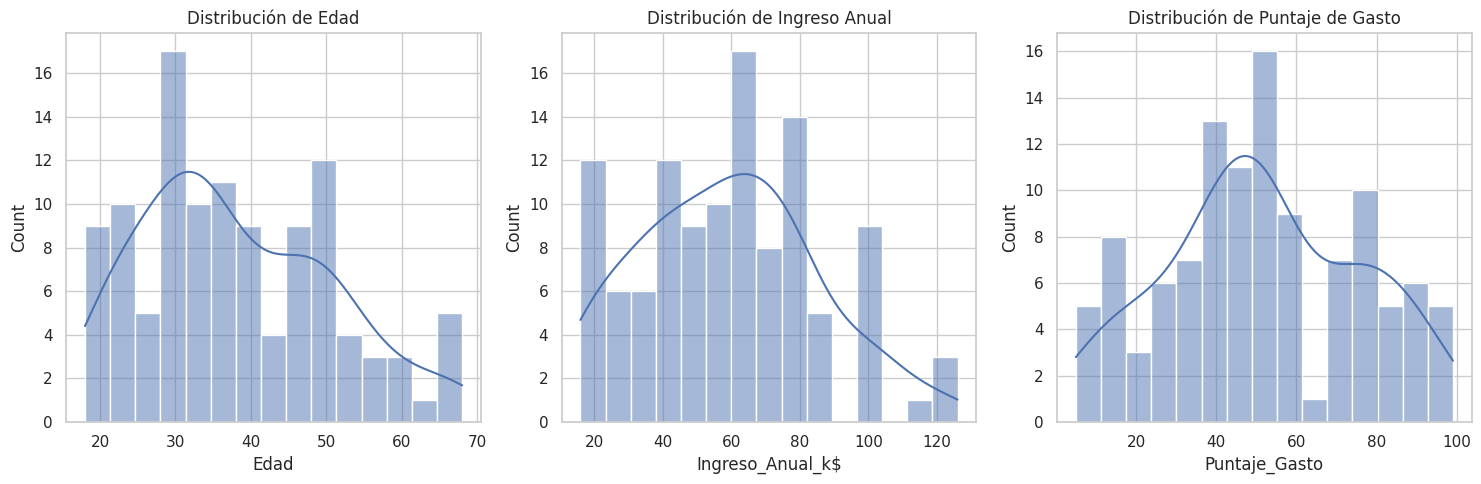

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilo de gráficas
sns.set(style="whitegrid")

# Crear figura
plt.figure(figsize=(15,5))

# Histograma Edad
plt.subplot(1,3,1)
sns.histplot(df_mujeres['Edad'], bins=15, kde=True)
plt.title('Distribución de Edad')

# Histograma Ingreso
plt.subplot(1,3,2)
sns.histplot(df_mujeres['Ingreso_Anual_k$'], bins=15, kde=True)
plt.title('Distribución de Ingreso Anual')

# Histograma Puntaje de Gasto
plt.subplot(1,3,3)
sns.histplot(df_mujeres['Puntaje_Gasto'], bins=15, kde=True)
plt.title('Distribución de Puntaje de Gasto')

# Mostrar gráficas
plt.tight_layout()
plt.show()

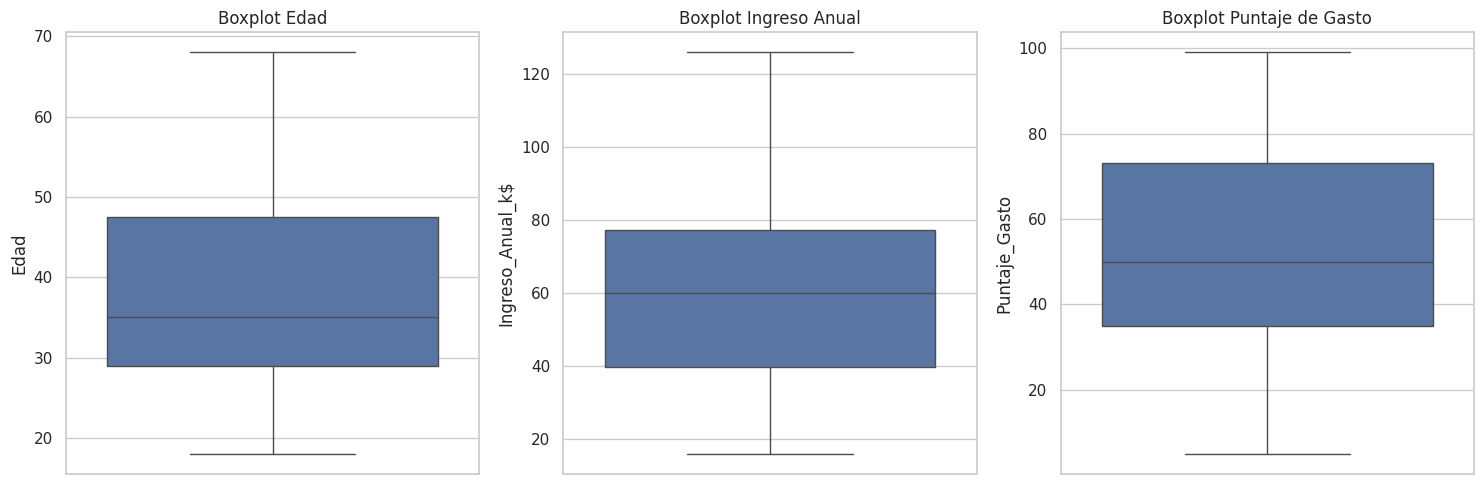

In [13]:

plt.figure(figsize=(15,5))

# Edad
plt.subplot(1,3,1)
sns.boxplot(y=df_mujeres['Edad'])
plt.title('Boxplot Edad')

# Ingreso
plt.subplot(1,3,2)
sns.boxplot(y=df_mujeres['Ingreso_Anual_k$'])
plt.title('Boxplot Ingreso Anual')

# Puntaje de gasto
plt.subplot(1,3,3)
sns.boxplot(y=df_mujeres['Puntaje_Gasto'])
plt.title('Boxplot Puntaje de Gasto')

plt.tight_layout()
plt.show()

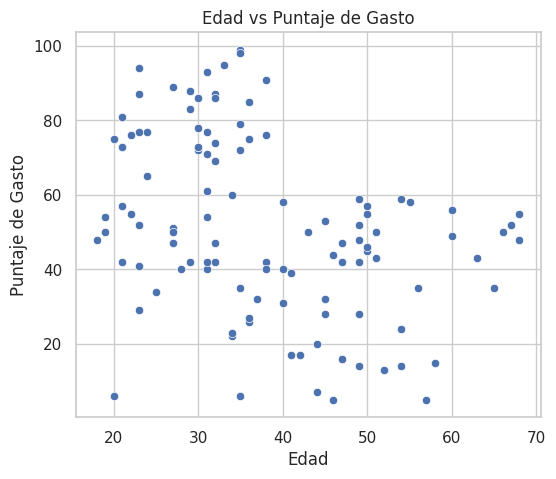

In [14]:

plt.figure(figsize=(6,5))

sns.scatterplot(
    x=df_mujeres['Edad'],
    y=df_mujeres['Puntaje_Gasto']
)

plt.title('Edad vs Puntaje de Gasto')
plt.xlabel('Edad')
plt.ylabel('Puntaje de Gasto')

plt.show()

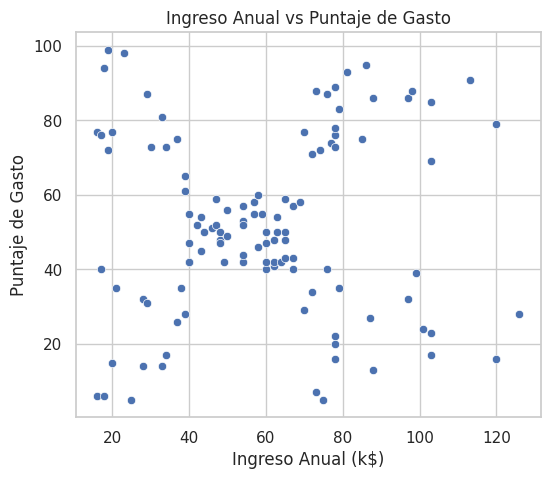

In [15]:

plt.figure(figsize=(6,5))

sns.scatterplot(
    x=df_mujeres['Ingreso_Anual_k$'],
    y=df_mujeres['Puntaje_Gasto']
)

plt.title('Ingreso Anual vs Puntaje de Gasto')
plt.xlabel('Ingreso Anual (k$)')
plt.ylabel('Puntaje de Gasto')

plt.show()

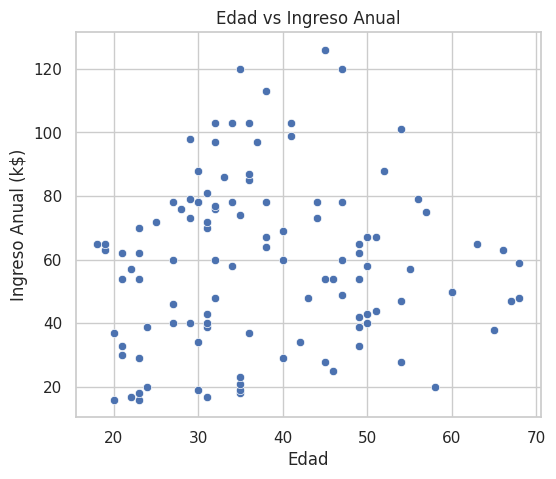

In [16]:

plt.figure(figsize=(6,5))

sns.scatterplot(
    x=df_mujeres['Edad'],
    y=df_mujeres['Ingreso_Anual_k$']
)

plt.title('Edad vs Ingreso Anual')
plt.xlabel('Edad')
plt.ylabel('Ingreso Anual (k$)')

plt.show()

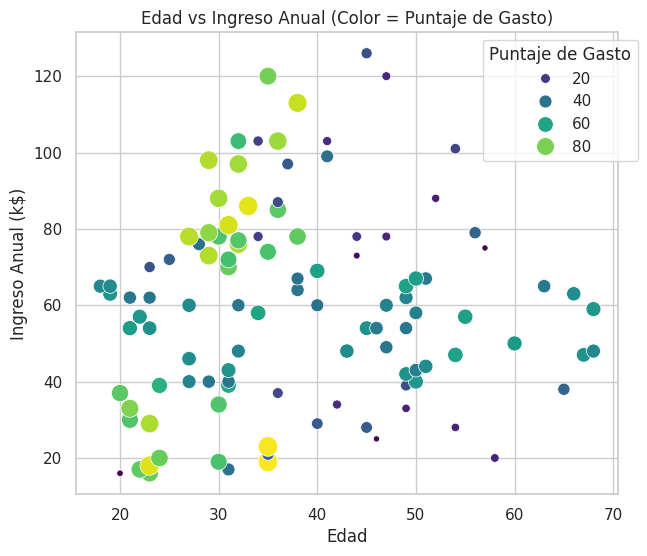

In [17]:

plt.figure(figsize=(7,6))

sns.scatterplot(
    x=df_mujeres['Edad'],
    y=df_mujeres['Ingreso_Anual_k$'],
    hue=df_mujeres['Puntaje_Gasto'],
    palette='viridis',
    size=df_mujeres['Puntaje_Gasto'],
    sizes=(20, 200)
)

plt.title('Edad vs Ingreso Anual (Color = Puntaje de Gasto)')
plt.xlabel('Edad')
plt.ylabel('Ingreso Anual (k$)')

plt.legend(title='Puntaje de Gasto', bbox_to_anchor=(1.05, 1))
plt.show()

In [18]:
# Función para detectar outliers usando IQR
def detectar_outliers(df, columna):
    Q1 = df[columna].quantile(0.25)
    Q3 = df[columna].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = df[(df[columna] < limite_inferior) | (df[columna] > limite_superior)]

    return outliers

# Aplicar a cada variable
outliers_edad = detectar_outliers(df_mujeres, 'Edad')
outliers_ingreso = detectar_outliers(df_mujeres, 'Ingreso_Anual_k$')
outliers_gasto = detectar_outliers(df_mujeres, 'Puntaje_Gasto')

# Mostrar resultados
print("Outliers en Edad:", len(outliers_edad))
print("Outliers en Ingreso:", len(outliers_ingreso))
print("Outliers en Gasto:", len(outliers_gasto))

Outliers en Edad: 0
Outliers en Ingreso: 0
Outliers en Gasto: 0


El análisis de correlación permite medir el grado de relación entre dos variables numéricas.

Su valor oscila entre -1 y 1:

* 1 → correlación positiva perfecta (ambas variables aumentan juntas)
* 0 → no existe relación
* -1 → correlación negativa perfecta (una aumenta mientras la otra disminuye)



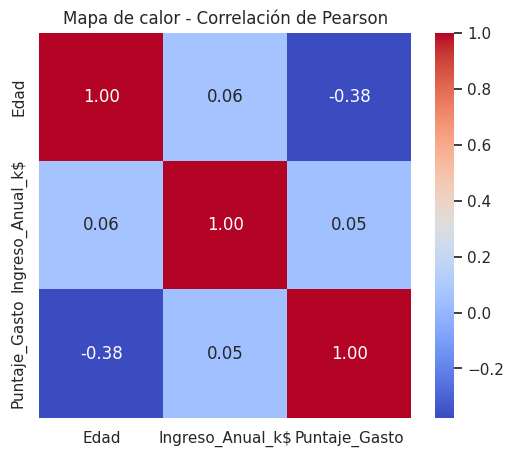

In [19]:
# Seleccionamos las variables numericas
df_num = df_mujeres[['Edad', 'Ingreso_Anual_k$', 'Puntaje_Gasto']]

# Calcular correlación
corr_pearson = df_num.corr(method='pearson')

# Graficar mapa de calor
plt.figure(figsize=(6,5))
sns.heatmap(corr_pearson, annot=True, cmap='coolwarm', fmt=".2f")

plt.title('Mapa de calor - Correlación de Pearson')
plt.show()

La correlación de Pearson mide la relación lineal entre variables.

Valores cercanos a 1 o -1 indican una relación fuerte, mientras que valores cercanos a 0 indican poca o ninguna relación lineal.

En este dataset, es común observar que la relación entre ingreso anual y puntaje de gasto no es estrictamente lineal, lo cual sugiere que pueden existir patrones más complejos que no son capturados completamente por esta métrica.


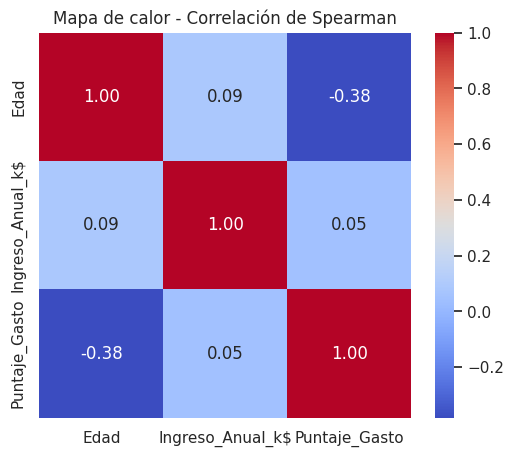

In [20]:

corr_spearman = df_num.corr(method='spearman')

plt.figure(figsize=(6,5))
sns.heatmap(corr_spearman, annot=True, cmap='coolwarm', fmt=".2f")

plt.title('Mapa de calor - Correlación de Spearman')
plt.show()

La correlación de Spearman evalúa relaciones monótonas, es decir, cuando una variable tiende a aumentar o disminuir consistentemente con otra, aunque no exista una relación lineal directa.

Esto es útil en datasets donde las relaciones pueden ser curvas o no lineales, como suele ocurrir en datos de comportamiento de clientes.

Comparar Pearson y Spearman permite identificar si existen relaciones ocultas que no son evidentes de forma lineal.


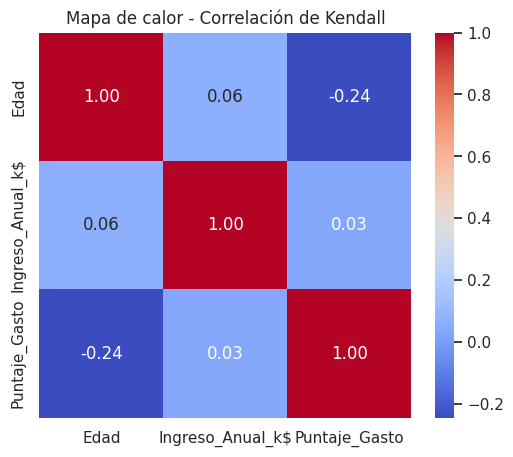

In [21]:

corr_kendall = df_num.corr(method='kendall')

plt.figure(figsize=(6,5))
sns.heatmap(corr_kendall, annot=True, cmap='coolwarm', fmt=".2f")

plt.title('Mapa de calor - Correlación de Kendall')
plt.show()

La correlación de Kendall mide la concordancia entre pares de observaciones, evaluando si el orden relativo entre los datos se mantiene entre variables.

Es una medida más robusta frente a valores atípicos y útil cuando se desea analizar relaciones basadas en rankings.

Aunque suele ser más conservadora que Pearson y Spearman, proporciona una visión adicional sobre la estructura de los datos.


In [22]:
# Seleccionamos variables numéricas relevantes
X = df_mujeres[['Edad', 'Ingreso_Anual_k$', 'Puntaje_Gasto']]

X.head()

,Edad,Ingreso_Anual_k$,Puntaje_Gasto
2,20,16,6
3,23,16,77
4,31,17,40
5,22,17,76
6,35,18,6


In [23]:
from sklearn.preprocessing import MinMaxScaler

# Crear el normalizador
scaler = MinMaxScaler()

# Aplicar transformación
X_norm = scaler.fit_transform(X)

# Convertir a DataFrame
X_norm = pd.DataFrame(X_norm, columns=X.columns)

# Mostrar primeras filas
X_norm.head()

,Edad,Ingreso_Anual_k$,Puntaje_Gasto
0,0.04,0.000000,0.010638
1,0.10,0.000000,0.765957
2,0.26,0.009091,0.372340
3,0.08,0.009091,0.755319
4,0.34,0.018182,0.010638


El método del codo se utiliza para determinar el número óptimo de clusters (k) en el algoritmo K-Means.

Consiste en ejecutar el algoritmo para diferentes valores de k y medir el error dentro de los clusters, conocido como inercia o SSE (Suma de Errores Cuadráticos).

A medida que aumenta el número de clusters, el error disminuye. Sin embargo, llega un punto donde la mejora deja de ser significativa. Este punto es conocido como "el codo" y representa el número óptimo de clusters.


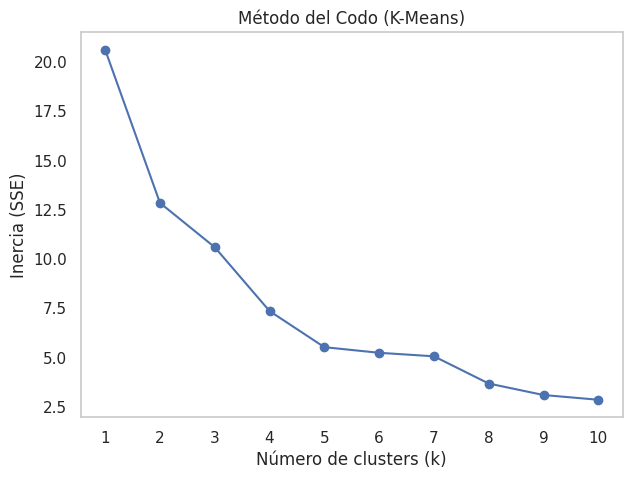

In [24]:

from sklearn.cluster import KMeans
inercia = []

k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        init='random',   # inicialización aleatoria
        n_init=1,        # solo una ejecución
        random_state=37
    )

    kmeans.fit(X_norm)
    inercia.append(kmeans.inertia_)

plt.figure(figsize=(7,5))
plt.plot(k_values, inercia, marker='o')

plt.title('Método del Codo (K-Means)')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Inercia (SSE)')

plt.xticks(k_values)
plt.grid()

plt.show()

In [25]:
from sklearn.cluster import KMeans

k = 5

resultados = []

for seed in range(10000):

    kmeans = KMeans(
        n_clusters=k,
        init='random',
        n_init=1,
        random_state=seed
    )

    kmeans.fit(X_norm)

    # Guardamos la inercia
    resultados.append({
        'seed': seed,
        'inercia': kmeans.inertia_
    })

# Convertir a DataFrame
resultados_df = pd.DataFrame(resultados)

# Mostrar resultados ordenados
resultados_df.sort_values(by='inercia')

,seed,inercia
797,797,5.533409
5834,5834,5.533409
1418,1418,5.533409
7792,7792,5.533409
5868,5868,5.533409
...,...,...
1697,1697,9.265095
3459,3459,9.268213
1887,1887,9.272285
6392,6392,9.407815


Para evaluar la calidad del modelo de clustering, se seleccionan métricas que consideran tanto la cohesión interna de los clusters como la separación entre ellos.

A diferencia de la inercia, que solo mide la compactación, estas métricas permiten evaluar la estructura global del agrupamiento.

El uso combinado de Silhouette, Davies-Bouldin y Calinski-Harabasz proporciona una evaluación más completa y robusta del modelo.


In [26]:

k = 5
seed = 797

from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=k,
    init='random',
    n_init=1,
    random_state=seed
)

kmeans.fit(X_norm)

labels = kmeans.labels_

df_mujeres["Cluster"] = kmeans.labels_

/tmp/ipykernel_30453/679284344.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_mujeres["Cluster"] = kmeans.labels_


In [27]:

from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

sse_kmeans = kmeans.inertia_

silhouette_kmeans = silhouette_score(X_norm, labels)
db_kmeans = davies_bouldin_score(X_norm, labels)
ch_kmeans = calinski_harabasz_score(X_norm, labels)

In [28]:

resultados = pd.DataFrame({
    "Algoritmo": ["KMeans"],
    "Seed": [seed],
    "Clusters (k)": [k],
    "SSE": [sse_kmeans],
    "Silhouette": [silhouette_kmeans],
    "Davies-Bouldin": [db_kmeans],
    "Calinski-Harabasz": [ch_kmeans]
})
resultados

,Algoritmo,Seed,Clusters (k),SSE,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,KMeans,797,5,5.533409,0.424404,0.850931,72.887837


In [29]:
cluster_profile_kmeans = (
    df_mujeres
    .groupby("Cluster")[["Edad", "Ingreso_Anual_k$", "Puntaje_Gasto"]]
    .mean()
)

cluster_profile_kmeans

,Edad,Ingreso_Anual_k$,Puntaje_Gasto
Cluster,,,
0,43.785714,93.285714,20.642857
1,25.461538,25.692308,80.538462
2,28.533333,50.100000,42.133333
3,32.545455,85.272727,80.590909
4,53.060606,49.000000,42.363636


In [30]:
kmeans_pp = KMeans(
    n_clusters=k,
    init='k-means++',
    n_init=1,
    random_state=seed
)

kmeans_pp.fit(X_norm)

labels_pp = kmeans_pp.labels_

In [31]:

silhouette_pp = silhouette_score(X_norm, labels_pp)
db_pp = davies_bouldin_score(X_norm, labels_pp)
ch_pp = calinski_harabasz_score(X_norm, labels_pp)

In [32]:

nueva_fila = pd.DataFrame({
    "Algoritmo": ["KMeans++"],
    "Seed": [seed],
    "Clusters (k)": [k],
    "Silhouette": [silhouette_pp],
    "Davies-Bouldin": [db_pp],
    "Calinski-Harabasz": [ch_pp]
})

resultados = pd.concat([resultados, nueva_fila], ignore_index=True)

resultados

,Algoritmo,Seed,Clusters (k),SSE,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,KMeans,797,5,5.533409,0.424404,0.850931,72.887837
1,KMeans++,797,5,NaN,0.423036,0.855237,72.730668


In [33]:

df_mujeres["Cluster_KPP"] = labels_pp

/tmp/ipykernel_30453/1604106128.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_mujeres["Cluster_KPP"] = labels_pp


In [34]:

cluster_profile_kpp = (
    df_mujeres
    .groupby("Cluster_KPP")[["Edad", "Ingreso_Anual_k$", "Puntaje_Gasto"]]
    .mean()
    .round(2)
)

cluster_profile_kpp

,Edad,Ingreso_Anual_k$,Puntaje_Gasto
Cluster_KPP,,,
0,28.14,50.83,42.52
1,52.58,47.48,42.24
2,32.55,85.27,80.59
3,44.60,92.33,21.60
4,25.46,25.69,80.54


In [35]:

k = 5
linkage = "average"   # se puede cambiar: ward, complete, average, single

In [36]:

from sklearn.cluster import AgglomerativeClustering

agglo = AgglomerativeClustering(
    n_clusters=k,
    linkage=linkage
)

labels_agglo = agglo.fit_predict(X_norm)

In [37]:

silhouette_agglo = silhouette_score(X_norm, labels_agglo)
db_agglo = davies_bouldin_score(X_norm, labels_agglo)
ch_agglo = calinski_harabasz_score(X_norm, labels_agglo)

In [38]:

nueva_fila = pd.DataFrame({
    "Algoritmo": [f"Agglomerative ({linkage})"],
    "Seed": ["N/A"],
    "Clusters (k)": [k],
    "Silhouette": [silhouette_agglo],
    "Davies-Bouldin": [db_agglo],
    "Calinski-Harabasz": [ch_agglo]
})

resultados = pd.concat([resultados, nueva_fila], ignore_index=True)

resultados

,Algoritmo,Seed,Clusters (k),SSE,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,KMeans,797,5,5.533409,0.424404,0.850931,72.887837
1,KMeans++,797,5,NaN,0.423036,0.855237,72.730668
2,Agglomerative (average),N/A,5,NaN,0.411238,0.894379,65.786765


In [39]:

df_mujeres["Cluster_Agglo"] = labels_agglo

/tmp/ipykernel_30453/4191726243.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_mujeres["Cluster_Agglo"] = labels_agglo


In [40]:

cluster_profile_agglo = (
    df_mujeres
    .groupby("Cluster_Agglo")[["Edad", "Ingreso_Anual_k$", "Puntaje_Gasto"]]
    .mean()
    .round(2)
)

cluster_profile_agglo

,Edad,Ingreso_Anual_k$,Puntaje_Gasto
Cluster_Agglo,,,
0,25.45,43.94,60.15
1,41.54,26.54,20.69
2,44.60,92.33,21.60
3,32.19,86.05,81.67
4,51.40,54.97,49.27


In [41]:

from sklearn.cluster import BisectingKMeans

In [42]:

k = 5
bisect_kmeans = BisectingKMeans(
    n_clusters=k,
    random_state=seed
)

labels_div = bisect_kmeans.fit_predict(X_norm)

In [43]:

silhouette_div = silhouette_score(X_norm, labels_div)
db_div = davies_bouldin_score(X_norm, labels_div)
ch_div = calinski_harabasz_score(X_norm, labels_div)

In [44]:

nueva_fila = pd.DataFrame({
    "Algoritmo": ["Divisivo (Bisecting K-Means)"],
    "Seed": [seed],
    "Clusters (k)": [k],
    "Silhouette": [silhouette_div],
    "Davies-Bouldin": [db_div],
    "Calinski-Harabasz": [ch_div]
})

resultados = pd.concat([resultados, nueva_fila], ignore_index=True)

resultados

,Algoritmo,Seed,Clusters (k),SSE,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,KMeans,797,5,5.533409,0.424404,0.850931,72.887837
1,KMeans++,797,5,NaN,0.423036,0.855237,72.730668
2,Agglomerative (average),N/A,5,NaN,0.411238,0.894379,65.786765
3,Divisivo (Bisecting K-Means),797,5,NaN,0.395347,0.954801,65.200204


In [45]:

df_mujeres["Cluster_Div"] = labels_div

/tmp/ipykernel_30453/2381732790.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_mujeres["Cluster_Div"] = labels_div


In [46]:

cluster_profile_div = (
    df_mujeres
    .groupby("Cluster_Div")[["Edad", "Ingreso_Anual_k$", "Puntaje_Gasto"]]
    .mean()
    .round(2)
)

cluster_profile_div

,Edad,Ingreso_Anual_k$,Puntaje_Gasto
Cluster_Div,,,
0,54.08,53.24,49.52
1,41.67,34.60,23.40
2,44.60,92.33,21.60
3,25.86,43.57,59.57
4,32.55,85.27,80.59


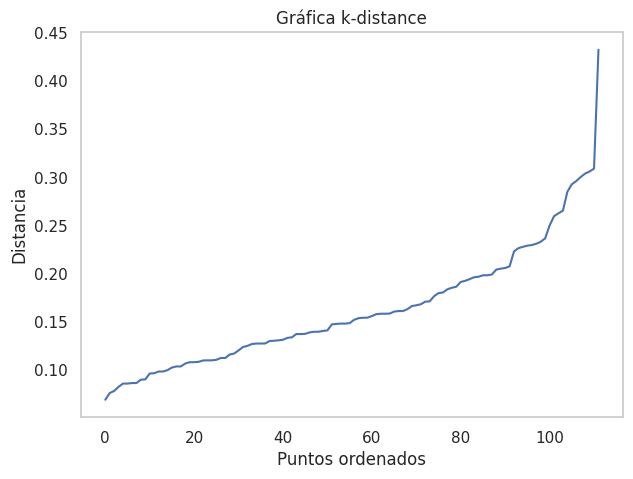

In [47]:

from sklearn.neighbors import NearestNeighbors
import numpy as np

min_samples = 5

neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X_norm)

distances, indices = neighbors_fit.kneighbors(X_norm)

distances = np.sort(distances[:, -1])

plt.figure(figsize=(7,5))
plt.plot(distances)

plt.title('Gráfica k-distance')
plt.xlabel('Puntos ordenados')
plt.ylabel('Distancia')

plt.grid()
plt.show()

In [48]:
min_samples = 6
eps = 0.3

In [49]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(
    eps=eps,
    min_samples=min_samples
)

labels_db = dbscan.fit_predict(X_norm)

In [50]:
for eps in [0.2, 0.3, 0.4, 0.5]:
    dbscan = DBSCAN(eps=eps, min_samples=6)
    labels = dbscan.fit_predict(X_norm)

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

    print(f"eps={eps} → clusters: {n_clusters}")

eps=0.2 → clusters: 2
eps=0.3 → clusters: 1
eps=0.4 → clusters: 1
eps=0.5 → clusters: 1


In [51]:
from sklearn.cluster import MeanShift, estimate_bandwidth

bandwidth = estimate_bandwidth(X_norm, quantile=0.1)

print("Bandwidth estimado:", bandwidth)

Bandwidth estimado: 0.24667170629580487


In [52]:

meanshift = MeanShift(
    bandwidth=bandwidth,
    bin_seeding=True
)

labels_ms = meanshift.fit_predict(X_norm)

In [53]:
import numpy as np

n_clusters_ms = len(np.unique(labels_ms))

print("Número de clusters:", n_clusters_ms)

Número de clusters: 7


In [54]:

silhouette_ms = silhouette_score(X_norm, labels_ms)
db_ms = davies_bouldin_score(X_norm, labels_ms)
ch_ms = calinski_harabasz_score(X_norm, labels_ms)

In [55]:
nueva_fila = pd.DataFrame({
    "Algoritmo": ["MeanShift"],
    "Seed": ["N/A"],
    "Clusters (k)": [n_clusters_ms],
    "Silhouette": [silhouette_ms],
    "Davies-Bouldin": [db_ms],
    "Calinski-Harabasz": [ch_ms]
})

resultados = pd.concat([resultados, nueva_fila], ignore_index=True)

resultados

,Algoritmo,Seed,Clusters (k),SSE,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,KMeans,797,5,5.533409,0.424404,0.850931,72.887837
1,KMeans++,797,5,NaN,0.423036,0.855237,72.730668
2,Agglomerative (average),N/A,5,NaN,0.411238,0.894379,65.786765
3,Divisivo (Bisecting K-Means),797,5,NaN,0.395347,0.954801,65.200204
4,MeanShift,N/A,7,NaN,0.435159,0.859369,73.723835


In [56]:

df_mujeres["Cluster_MS"] = labels_ms

cluster_profile_ms = (
    df_mujeres
    .groupby("Cluster_MS")[["Edad", "Ingreso_Anual_k$", "Puntaje_Gasto"]]
    .mean()
    .round(2)
)

cluster_profile_ms

/tmp/ipykernel_30453/2996255413.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_mujeres["Cluster_MS"] = labels_ms


,Edad,Ingreso_Anual_k$,Puntaje_Gasto
Cluster_MS,,,
0,52.13,55.67,48.43
1,25.86,55.90,47.52
2,32.19,86.05,81.67
3,25.46,25.69,80.54
4,43.79,93.29,20.64
5,45.40,29.40,21.70
6,28.67,17.00,17.33


# AIC Y BIC

 AIC (Akaike Information Criterion)

 AIC =$ -2 * log(L) + 2k$

 BIC (Bayesian Information Criterion)

 BIC =$ -2 * log(L) + k * log(n)$


 L  -> Likelihood (verosimilitud del modelo)
       Qué tan bien el modelo explica los datos.
       Mientras mayor sea L, mejor ajusta el modelo.

 k  -> Número de parámetros del modelo
       Representa la complejidad del modelo.
       Ejemplo: en GMM depende del número de clusters y dimensiones.

 n  -> Número de observaciones (datos)
       Cantidad total de puntos en el dataset.

 AIC y BIC buscan un balance entre:
 1) Buen ajuste del modelo (log(L) alto)
 2) Baja complejidad (k pequeño)

 Penalizan modelos demasiado complejos para evitar overfitting.

 AIC penaliza menos la complejidad:
     $+ 2k$

 BIC penaliza más la complejidad:
     $+ k * log(n)$


 El mejor modelo es el que tenga el MENOR valor de AIC o BIC


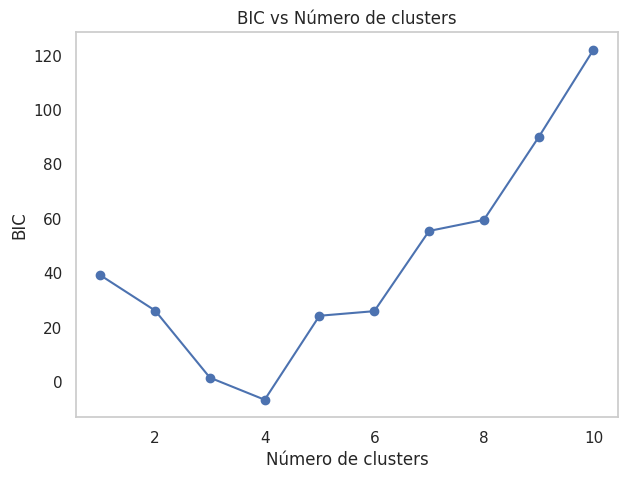

In [57]:
from sklearn.mixture import GaussianMixture

bic_scores = []
k_values = range(1, 11)

for k in k_values:
    gmm = GaussianMixture(
        n_components=k,
        covariance_type='full',
        random_state=seed
    )

    gmm.fit(X_norm)
    bic_scores.append(gmm.bic(X_norm))

# Graficar
plt.figure(figsize=(7,5))
plt.plot(k_values, bic_scores, marker='o')

plt.title('BIC vs Número de clusters')
plt.xlabel('Número de clusters')
plt.ylabel('BIC')

plt.grid()
plt.show()

In [58]:

k = 4

gmm = GaussianMixture(
    n_components=k,
    covariance_type='full', #'full', 'tied', 'diag', 'spherical'
    random_state=seed
)

gmm.fit(X_norm)

labels_gmm = gmm.predict(X_norm)

In [59]:
probs = gmm.predict_proba(X_norm)

probs[:5]

array([[8.88607501e-19, 9.99999938e-01, 4.78556942e-26, 6.18792759e-08],
       [9.99967461e-01, 2.71836951e-08, 3.25116664e-05, 6.08206861e-18],
       [1.99605343e-05, 9.99979470e-01, 3.12096425e-08, 5.37987431e-07],
       [9.99967385e-01, 6.72126816e-08, 3.25474234e-05, 1.92988340e-17],
       [2.82860607e-18, 9.99977334e-01, 5.97484354e-22, 2.26657098e-05]])

In [60]:
silhouette_gmm = silhouette_score(X_norm, labels_gmm)
db_gmm = davies_bouldin_score(X_norm, labels_gmm)
ch_gmm = calinski_harabasz_score(X_norm, labels_gmm)

In [61]:
nueva_fila = pd.DataFrame({
    "Algoritmo": ["GMM"],
    "Seed": [seed],
    "Clusters (k)": [k],
    "Silhouette": [silhouette_gmm],
    "Davies-Bouldin": [db_gmm],
    "Calinski-Harabasz": [ch_gmm]
})

resultados = pd.concat([resultados, nueva_fila], ignore_index=True)

resultados

,Algoritmo,Seed,Clusters (k),SSE,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,KMeans,797,5,5.533409,0.424404,0.850931,72.887837
1,KMeans++,797,5,NaN,0.423036,0.855237,72.730668
2,Agglomerative (average),N/A,5,NaN,0.411238,0.894379,65.786765
3,Divisivo (Bisecting K-Means),797,5,NaN,0.395347,0.954801,65.200204
4,MeanShift,N/A,7,NaN,0.435159,0.859369,73.723835
5,GMM,797,4,NaN,0.358494,1.018069,57.021185


In [62]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_std = scaler.fit_transform(
    df_mujeres[["Edad", "Ingreso_Anual_k$", "Puntaje_Gasto"]]
)

In [63]:
gmm.fit(X_std)
labels_gmm = gmm.predict(X_std)
probs = gmm.predict_proba(X_std)

In [64]:
gmm.fit(X_std)
labels_gmm = gmm.predict(X_std)
probs = gmm.predict_proba(X_std)

In [65]:
from sklearn.mixture import GaussianMixture

k = 5

gmm = GaussianMixture(
    n_components=k,
    covariance_type='full',
    random_state=seed
)

gmm.fit(X_std)

labels_gmm = gmm.predict(X_std)

probs = gmm.predict_proba(X_std)

In [66]:

from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

sil_gmm = silhouette_score(X_std, labels_gmm)
db_gmm = davies_bouldin_score(X_std, labels_gmm)
ch_gmm = calinski_harabasz_score(X_std, labels_gmm)

In [67]:

nueva_fila = pd.DataFrame({
    "Algoritmo": ["GMM"],
    "Clusters (k)": [k],
    "Silhouette": [sil_gmm],
    "Davies-Bouldin": [db_gmm],
    "Calinski-Harabasz": [ch_gmm]
})

resultados = pd.concat([resultados, nueva_fila], ignore_index=True)

resultados

,Algoritmo,Seed,Clusters (k),SSE,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,KMeans,797,5,5.533409,0.424404,0.850931,72.887837
1,KMeans++,797,5,NaN,0.423036,0.855237,72.730668
2,Agglomerative (average),N/A,5,NaN,0.411238,0.894379,65.786765
3,Divisivo (Bisecting K-Means),797,5,NaN,0.395347,0.954801,65.200204
4,MeanShift,N/A,7,NaN,0.435159,0.859369,73.723835
5,GMM,797,4,NaN,0.358494,1.018069,57.021185
6,GMM,NaN,5,NaN,0.402844,0.923039,63.343678


In [68]:

import numpy as np

df_mujeres["Cluster_GMM"] = np.argmax(probs, axis=1)

/tmp/ipykernel_30453/1723504561.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_mujeres["Cluster_GMM"] = np.argmax(probs, axis=1)


In [69]:
df_mujeres["Prob_Max"] = np.max(probs, axis=1)

/tmp/ipykernel_30453/687704707.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_mujeres["Prob_Max"] = np.max(probs, axis=1)


In [70]:

cluster_profile_gmm = (
    df_mujeres
    .groupby("Cluster_GMM")[["Edad", "Ingreso_Anual_k$", "Puntaje_Gasto"]]
    .mean()
    .round(2)
)

cluster_profile_gmm

,Edad,Ingreso_Anual_k$,Puntaje_Gasto
Cluster_GMM,,,
0,25.25,43.44,60.72
1,43.21,27.36,21.71
2,32.19,86.05,81.67
3,43.79,93.29,20.64
4,50.48,56.45,49.03



###  Silhouette Score (mas alto mejor)
Mide qué tan bien separado está cada cluster respecto a los demás.




###  Davies-Bouldin Index ( mas bajo mejor)
Evalúa la similitud entre clusters.




###  Calinski-Harabasz Index (mas alto mejor)
Mide la relación entre dispersión interna y separación entre clusters.




In [71]:
resultados

,Algoritmo,Seed,Clusters (k),SSE,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,KMeans,797,5,5.533409,0.424404,0.850931,72.887837
1,KMeans++,797,5,NaN,0.423036,0.855237,72.730668
2,Agglomerative (average),N/A,5,NaN,0.411238,0.894379,65.786765
3,Divisivo (Bisecting K-Means),797,5,NaN,0.395347,0.954801,65.200204
4,MeanShift,N/A,7,NaN,0.435159,0.859369,73.723835
5,GMM,797,4,NaN,0.358494,1.018069,57.021185
6,GMM,NaN,5,NaN,0.402844,0.923039,63.343678


In [84]:
# Creamos un dataframe limpio SOLO con MeanShift
df_meanshift = df_mujeres[[
    "ID_Cliente",
    "Edad",
    "Ingreso_Anual_k$",
    "Puntaje_Gasto",
    "Cluster_MS"
]].copy()

# Obtenemos la lista de clusters únicos
clusters = sorted(df_meanshift["Cluster_MS"].unique())

# Recorremos cada cluster
for cid in clusters:

    # Filtramos clientes del cluster
    df_cluster = df_meanshift[df_meanshift["Cluster_MS"] == cid]

    # Guardamos SOLO info de MeanShift
    df_cluster.to_csv(f"clientes_meanshift_perfil_{cid}.csv", index=False)

# Mostramos clusters
clusters

#Esto es para tener la informacion de cada segmento de clientes y enviarlo a
#las personas respondables de las ofertas

[np.int64(0),
 np.int64(1),
 np.int64(2),
 np.int64(3),
 np.int64(4),
 np.int64(5),
 np.int64(6)]

In [85]:
# Tabla de perfiles para MeanShift
perfiles_ms = pd.DataFrame({
    "cluster": [0, 1, 2, 3, 4, 5, 6],
    "nombre_perfil": [
        "Adultas equilibradas",
        "Jóvenes consumo moderado",
        "VIP alto valor",
        "Jóvenes impulsivas",
        "Alto ingreso bajo gasto",
        "Adultas austeras",
        "Bajo ingreso bajo consumo"
    ],
    "descripcion": [
        "Mujeres mayores con ingresos medios y gasto moderado. Consumo estable.",
        "Jóvenes con ingreso medio y gasto medio. Consumo ocasional.",
        "Clientes con altos ingresos y alto gasto. Segmento más valioso.",
        "Jóvenes con bajo ingreso pero alto gasto. Compras impulsivas.",
        "Altos ingresos pero poco gasto. Potencial de crecimiento.",
        "Adultas con ingresos bajos y poco gasto. Consumo conservador.",
        "Clientes con muy bajo ingreso y bajo gasto. Bajo valor comercial."
    ],
    "estrategia_marketing": [
        "Promociones estables, programas de lealtad.",
        "Marketing en redes, promociones moderadas.",
        "Preventas exclusivas, productos premium, experiencias VIP.",
        "Ofertas flash, descuentos limitados, marketing emocional.",
        "Descuentos personalizados para incentivar compra.",
        "Ofertas básicas, paquetes económicos.",
        "Promociones simples y bajo costo."
    ]
})

perfiles_ms

,cluster,nombre_perfil,descripcion,estrategia_marketing
0,0,Adultas equilibradas,Mujeres mayores con ingresos medios y gasto mo...,"Promociones estables, programas de lealtad."
1,1,Jóvenes consumo moderado,Jóvenes con ingreso medio y gasto medio. Consu...,"Marketing en redes, promociones moderadas."
2,2,VIP alto valor,Clientes con altos ingresos y alto gasto. Segm...,"Preventas exclusivas, productos premium, exper..."
3,3,Jóvenes impulsivas,Jóvenes con bajo ingreso pero alto gasto. Comp...,"Ofertas flash, descuentos limitados, marketing..."
4,4,Alto ingreso bajo gasto,Altos ingresos pero poco gasto. Potencial de c...,Descuentos personalizados para incentivar compra.
5,5,Adultas austeras,Adultas con ingresos bajos y poco gasto. Consu...,"Ofertas básicas, paquetes económicos."
6,6,Bajo ingreso bajo consumo,Clientes con muy bajo ingreso y bajo gasto. Ba...,Promociones simples y bajo costo.


In [86]:
df_meanshift = df_mujeres[[
    "ID_Cliente",
    "Edad",
    "Ingreso_Anual_k$",
    "Puntaje_Gasto",
    "Cluster_MS",
]].copy()

df_meanshift.head()

,ID_Cliente,Edad,Ingreso_Anual_k$,Puntaje_Gasto,Cluster_MS
2,3,20,16,6,6
3,4,23,16,77,3
4,5,31,17,40,6
5,6,22,17,76,3
6,7,35,18,6,6


In [87]:
#Unimos la info de las clientas con su respectivo perfil
df_meanshift = df_meanshift.merge(
    perfiles_ms,
    left_on="Cluster_MS",
    right_on="cluster",
    how="left"
)

In [88]:
#finalmente creamos un excel para la persona que lo requiera y tenga la info completa y limpia de lo que encontramos
df_meanshift.to_excel("clientes_meanshift_con_perfiles.xlsx", index=False)

## Estrategia de Marketing basada en Clustering (MeanShift)

En este proyecto se utilizaron distintos algoritmos de clustering para segmentar clientes, siendo el algoritmo MeanShift el mejor para la segmentacion de este negocio

A diferencia de otros algoritmos como K-Means, MeanShift no necesita que se le indique el número de grupos, lo que permite encontrar patrones naturales en los datos.

Se compararon diferentes algoritmos usando métricas de evaluación:

- Silhouette Score (más alto mejor)
- Davies-Bouldin (más bajo mejor)
- Calinski-Harabasz (más alto mejor)

MeanShift obtuvo los mejores resultados en la mayoría de métricas, lo que indica que genera clusters mejor definidos.

A partir de los clusters obtenidos, se crearon perfiles de clientes basados en:

- Edad
- Ingreso anual
- Nivel de gasto

Esto permite entender mejor el comportamiento de compra.

Cada cliente fue clasificada en un perfil específico, y a partir de ello se generaron recomendaciones como:

- Preventas exclusivas
- Descuentos personalizados
- Promociones en redes sociales
- Ofertas flash

El uso de clustering permite pasar de datos a decisiones.

En lugar de tratar a todos los clientes igual, ahora el negocio puede:

- Personalizar ofertas
- Aumentar ventas
- Mejorar la experiencia del cliente
